![](../assets/spun_logo.png)


# SPUN Quickstart: Inference & Mosaicking 🏔️🛰️

This notebook demonstrates how to run the SPUN (Snow Patch U-Net) model on custom regions of interest. 

We will cover two approaches to handling Earth Engine data:
1. **Raw Tile Retrieval:** Fetching every single satellite pass over an area.
2. **Cloud-Optimized Mosaics:** Combining overlapping passes to look "through" moving clouds and retrieve the maximum amount of clear-sky snow data per day.

<div class="alert alert-block alert-info">
    <b>Note: </b>This tutorial can run on CPU or GPU but for larger regions GPU will be faster.
</div>

<!-- Google Colab offer free GPU time. Colab notebooks coming soon... -->

<!-- <a href="https://colab.research.google.com/github/leamhowe/spun/tree/main/example_notebooks/01_quickstart_inference.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> -->

<!-- ## Requirements:
<div class="alert alert-block alert-warning">
    - Environment created using spun_environment.yml, see README.md for details.
    - Google Earth Engine account
</div> -->

---

> **⚠️ Requirements**
> Environment created using spun_environment.yml, see README.md for details.
> Google Earth Engine account

---

## Download SPUN

The trained SPUN model can be downloaded from: https://doi.org/10.5281/zenodo.20055817 

In [ ]:
import urllib.request

ZENODO_URL = "https://zenodo.org/records/20055817/SPUN.pt"

# Define the exact path where it should live in the root directory
weights_path = "../SPUN.pt"

# If the model isn't there, download it automatically!
if not weights_path.exists():
    print(f"Downloading pre-trained model from Zenodo to {weights_path}...")
    urllib.request.urlretrieve(ZENODO_URL, weights_path)
    print("Download complete!")

## Setup & Config

In [ ]:
import sys
# Aggressively remove the rogue ~/.local folder from Python's search path (JASMIN HPC fix)
sys.path = [p for p in sys.path if '.local' not in p]

import os
import json
import torch
import ee

# Add repository root to the path
repo_root = os.path.abspath('..')
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

# Import our custom utilities
from src.utils.gee_utils import authenticate_ee, get_individual_s2_tiles, get_daily_cloud_optimized_mosaics
from src.utils.inference_utils import instantiate_model, predict_batched

# Authenticate Earth Engine
ee.Authenticate()
ee.Initialize()
# Alternatively, authenticate with Earth Engine service account then you won't have to sign in every session: https://developers.google.com/earth-engine/guides/service_account
# CREDENTIALS_PATH = 'path/to/ee-credentials.json'
# authenticate_ee(CREDENTIALS_PATH)

# --- USER CONFIGURATION ---
GEOJSON_PATH = 'scotland_cairngorm.geojson' 
START_DATE = '2026-04-25'
END_DATE = '2026-05-10' 
MODEL_WEIGHTS = '../SPUN.pt'

# Set maximum allowed cloud cover percentage for the ROI (0-100)
# Setting this to 60.0 means it will skip any images that are more than 60% cloudy. We keep it at 100% for this example to show SPUN can handle cloud.
MAX_CLOUD_COVER = 100.0 

# Set clear threshold against which the CloudScore+ cs_cdf product is thresholded to mask cloud. Standard that was used in training SPUN was 0.5. But you can increase this if you want to mask cloud more strictly. 
# See https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_CLOUD_SCORE_PLUS_V1_S2_HARMONIZED for more details.
# there is an interactive app to explore the threshold here: https://earthengine-ai.projects.earthengine.app/view/cloud-score-plus-collection-explorer
CLEAR_THRESHOLD = 0.50 

BANDS = ['B1','B2','B3','B4','B5','B6','B7','B8','B8A','B9','B10','B11','B12'] # bands required by SPUN
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Earth Engine Initialised Successfully!
Using device: cuda


## Setup Visualization
Before we fetch the data, let's define a reusable plotting function. This keeps our inference loops clean while allowing us to easily tweak the visual output (colormaps, thresholds, etc.).

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

def plot_snow_maps(title_text, img_array, prediction_np):
    """Generates a 1x3 plot showing RGB, Continuous SCF, and Binary Snow Mask."""
    # Extract RGB (Bands 4, 3, 2 which are indices 3, 2, 1)
    rgb = np.stack([img_array[:, :, 3], img_array[:, :, 2], img_array[:, :, 1]], axis=-1)
    rgb_bright = np.power(np.clip(rgb, 0, 1), 0.65) # Gamma correction
    
    is_cloud = (prediction_np == 200)
    scf_masked = np.ma.masked_where(is_cloud, prediction_np)
    
    binary_map = np.zeros_like(prediction_np, dtype=np.int8)
    binary_map[(~is_cloud) & (prediction_np > 50.0)] = 1
    binary_map[is_cloud] = 2

    # --- Plotting ---
    cmap_scf = plt.get_cmap('viridis')
    cmap_scf.set_bad(color='red')
    cmap_bin = mcolors.ListedColormap(['black', 'cyan', 'red'])
    norm_bin = mcolors.BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap_bin.N)

    fig, axs = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(title_text, fontsize=14, fontweight='bold')

    axs[0].imshow(rgb_bright)
    axs[0].set_title('Sentinel-2 RGB', fontsize=12)
    axs[0].axis('off')

    im2 = axs[1].imshow(scf_masked, cmap=cmap_scf, vmin=0, vmax=100)
    axs[1].set_title('SPUN Predicted SCF', fontsize=12)
    axs[1].axis('off')
    fig.colorbar(im2, ax=axs[1], fraction=0.046, pad=0.04, label='Snow Fraction (%)')

    axs[2].imshow(binary_map, cmap=cmap_bin, norm=norm_bin, interpolation='nearest')
    axs[2].set_title('Binary Snow Mask', fontsize=12)
    axs[2].axis('off')

    patches = [
        mpatches.Patch(color='black', label='Ground'),
        mpatches.Patch(color='cyan', label='Snow'),
        mpatches.Patch(color='red', label='Cloud / No Data')
    ]
    axs[2].legend(handles=patches, loc='lower right', framealpha=0.9)

    plt.tight_layout()
    plt.show()

## Part 1: Predicting on Raw Satellite Passes

Sentinel-2 data is divided into 100km × 100km "MGRS Tiles". When your Region of Interest (ROI) crosses a tile boundary, or when overlapping satellite orbits occur, you will often find multiple images taken on the *exact same day*, just seconds or minutes apart.

First, let's fetch every individual raw tile to see what the model does with these fragmented, cloudy passes.

In [13]:
# 1. Load GeoJSON to Earth Engine Geometry
with open(GEOJSON_PATH, 'r') as f:
    coords = json.load(f)['features'][0]['geometry']['coordinates']
roi = ee.Geometry.Polygon(coords)

# 2. Fetch Raw Tiles
print("Fetching raw, individual Sentinel-2 tiles...")
raw_images = get_individual_s2_tiles(roi, START_DATE, END_DATE, BANDS, max_cloud_cover=MAX_CLOUD_COVER, clear_threshold=CLEAR_THRESHOLD)

Fetching raw, individual Sentinel-2 tiles...
Found 9 individual optical tile(s). Evaluating cloud cover...
Analyzing Tile 1/9 from 2026-04-26 11:35:21...
  -> ROI is 16.8% cloudy. Downloading 13-band optical data...
Analyzing Tile 2/9 from 2026-04-26 11:45:38...
  -> ROI is 23.7% cloudy. Downloading 13-band optical data...
Analyzing Tile 3/9 from 2026-04-29 11:45:18...
  -> ROI is 1.8% cloudy. Downloading 13-band optical data...
Analyzing Tile 4/9 from 2026-05-01 11:35:26...
  -> ROI is 100.0% cloudy. Downloading 13-band optical data...
Analyzing Tile 5/9 from 2026-05-03 11:35:39...
  -> ROI is 100.0% cloudy. Downloading 13-band optical data...
Analyzing Tile 6/9 from 2026-05-04 11:45:22...
  -> ROI is 42.0% cloudy. Downloading 13-band optical data...
Analyzing Tile 7/9 from 2026-05-06 11:35:22...
  -> ROI is 99.3% cloudy. Downloading 13-band optical data...
Analyzing Tile 8/9 from 2026-05-06 11:45:34...
  -> ROI is 100.0% cloudy. Downloading 13-band optical data...
Analyzing Tile 9/9 


Loading SPUN Model...

--- Running Inference on Raw Tiles ---

Predicting on: 2026-04-26 11:35:21


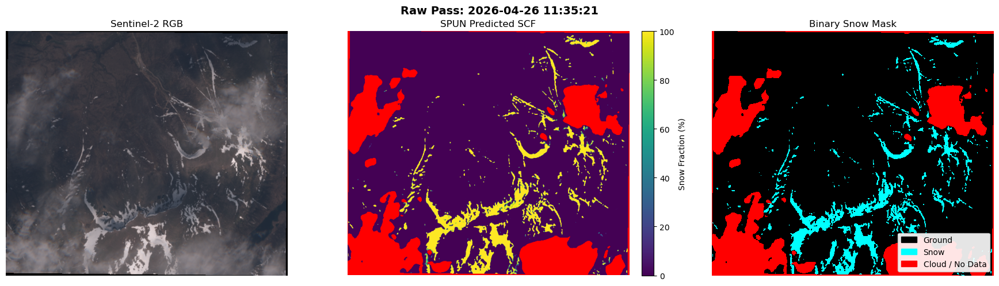


Predicting on: 2026-04-26 11:45:38


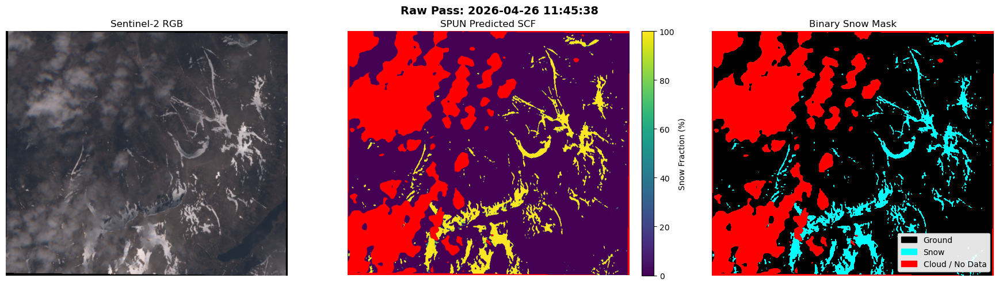


Predicting on: 2026-04-29 11:45:18


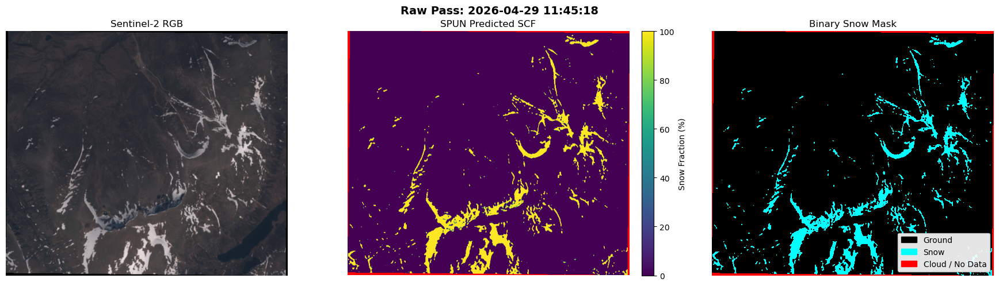


Predicting on: 2026-05-01 11:35:26


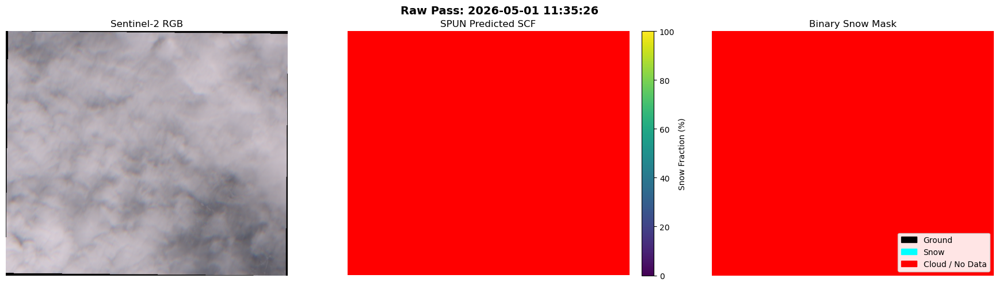


Predicting on: 2026-05-03 11:35:39


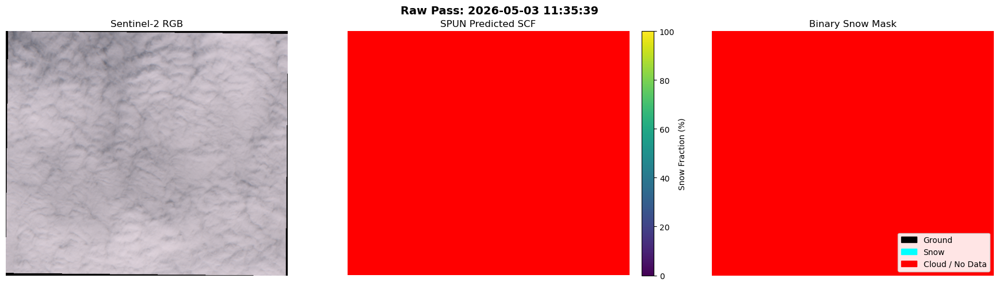


Predicting on: 2026-05-04 11:45:22


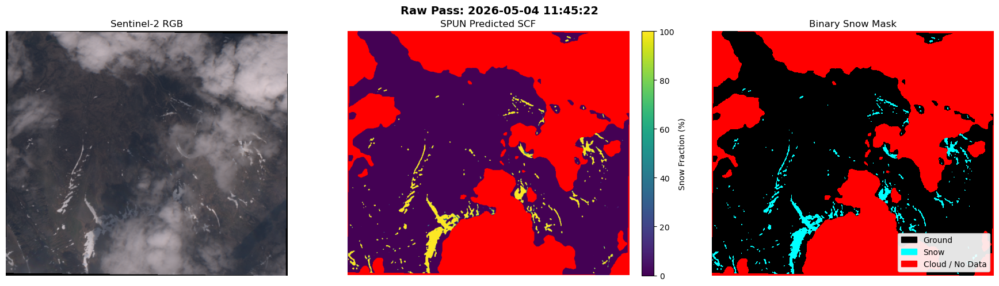


Predicting on: 2026-05-06 11:35:22


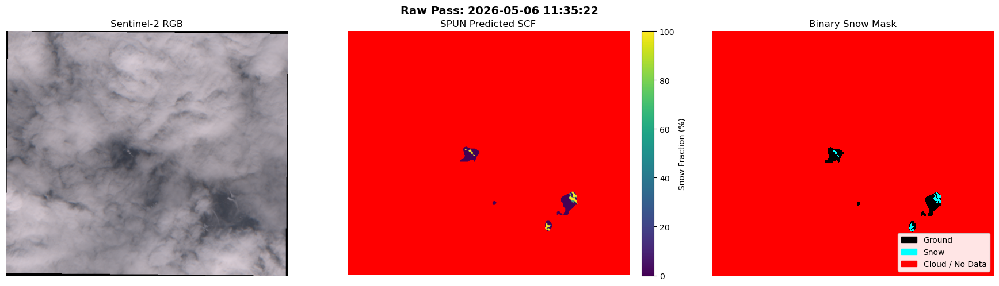


Predicting on: 2026-05-06 11:45:34


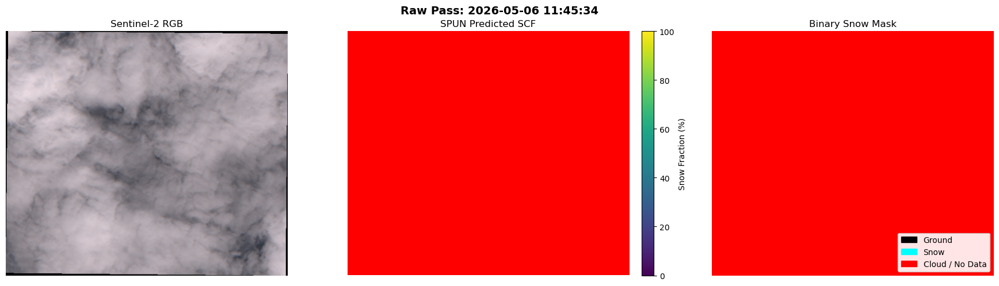


Predicting on: 2026-05-09 11:45:18


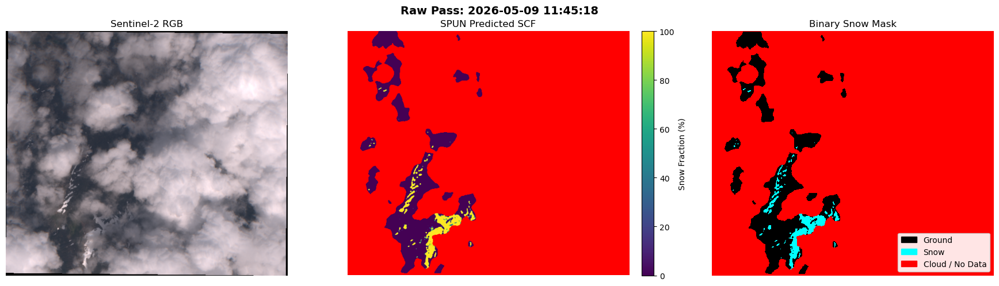

In [14]:
# 3. Load Model
print("\nLoading SPUN Model...")
model = instantiate_model(MODEL_WEIGHTS, BANDS, backbone='resnet50', device=device)

# 4. Predict
print("\n--- Running Inference on Raw Tiles ---")
for item in raw_images:
    if item['optical'] is None: continue
        
    print(f"\nPredicting on: {item['date']}")
    prediction_np = predict_batched(
        model=model, image_array=item['optical'], device=device, 
        batch_size=16, num_workers=0, cloud_mask_array=item['cloud_mask']
    )
    
    plot_snow_maps(f"Raw Pass: {item['date']}", item['optical'], prediction_np)

## Part 2: The Cloud-Optimized Mosaic

Looking at individual passes is great, but as you can see above, clouds often obscure the snow, and overlapping tile boundaries can cut our ROI in half. 

Because clouds move, different satellite passes on the same day might have clear views of *different parts of the mountain*. We can use Google Earth Engine's `qualityMosaic` function to dynamically drill down through all overlapping images on a given day, selecting only the pixels with the highest clear-sky probability (`cs_cdf`).

This yields a single, seamless, "best possible" snow map for each day.

In [16]:
# 1. Fetch Cloud-Optimized Daily Mosaics
print("Building and fetching Cloud-Optimized Daily Mosaics...")
optimized_images = get_daily_cloud_optimized_mosaics(roi, START_DATE, END_DATE, BANDS, max_cloud_cover=MAX_CLOUD_COVER, clear_threshold=CLEAR_THRESHOLD)

Building and fetching Cloud-Optimized Daily Mosaics...
Found 9 raw tiles grouped into 7 unique day(s).
Analyzing daily composite for: 2026-04-26...
  -> Composite is 6.3% cloudy. Downloading 13-band optical data...
Analyzing daily composite for: 2026-04-29...
  -> Composite is 0.0% cloudy. Downloading 13-band optical data...
Analyzing daily composite for: 2026-05-01...
  -> Composite is 100.0% cloudy. Downloading 13-band optical data...
Analyzing daily composite for: 2026-05-03...
  -> Composite is 100.0% cloudy. Downloading 13-band optical data...
Analyzing daily composite for: 2026-05-04...
  -> Composite is 41.2% cloudy. Downloading 13-band optical data...
Analyzing daily composite for: 2026-05-06...
  -> Composite is 99.3% cloudy. Downloading 13-band optical data...
Analyzing daily composite for: 2026-05-09...
  -> Composite is 90.8% cloudy. Downloading 13-band optical data...



--- Running Inference on Optimized Mosaics ---

Predicting on Daily Composite: 2026-04-26


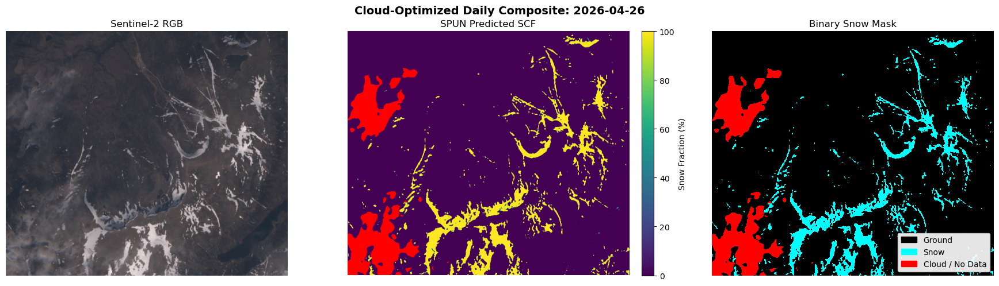


Predicting on Daily Composite: 2026-04-29


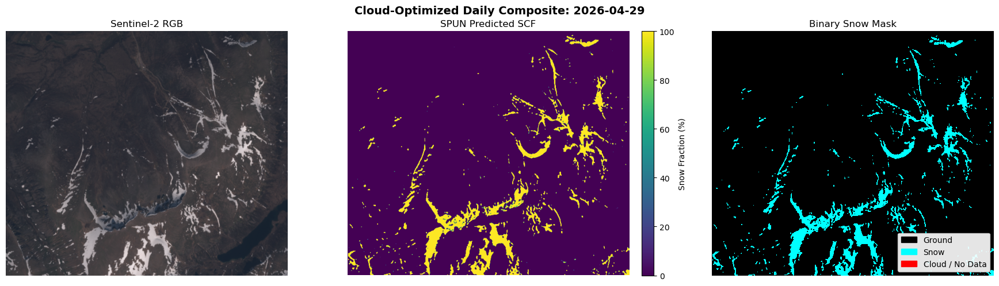


Predicting on Daily Composite: 2026-05-01


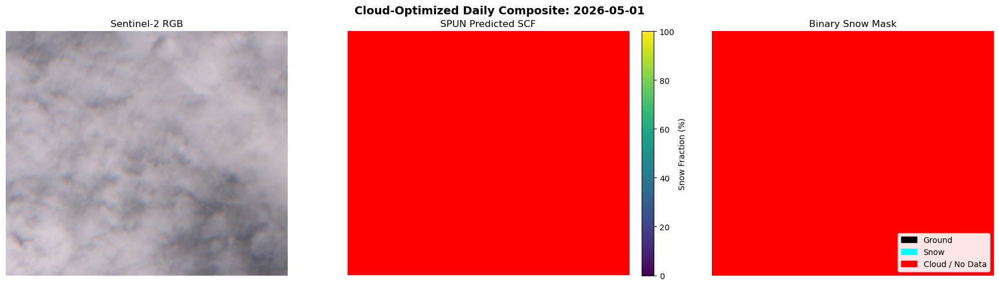


Predicting on Daily Composite: 2026-05-03


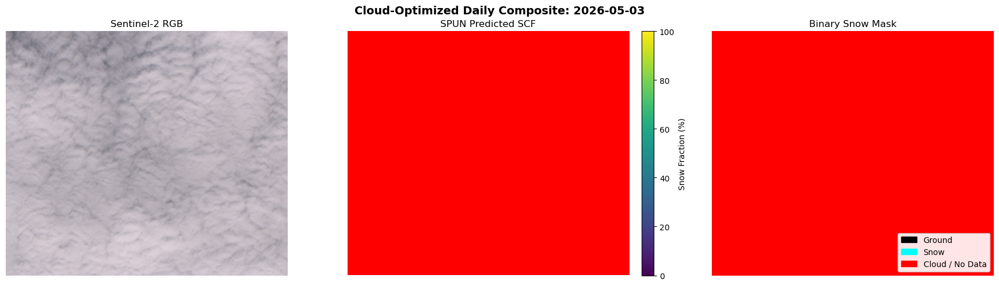


Predicting on Daily Composite: 2026-05-04


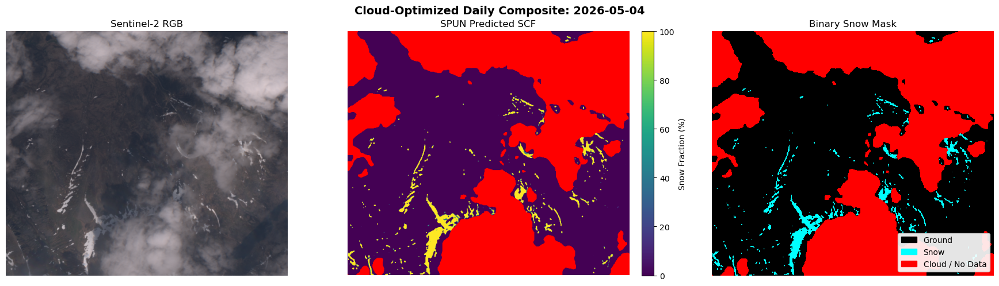


Predicting on Daily Composite: 2026-05-06


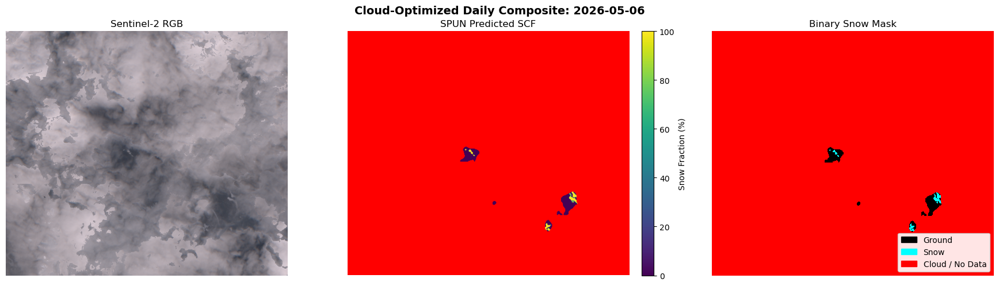


Predicting on Daily Composite: 2026-05-09


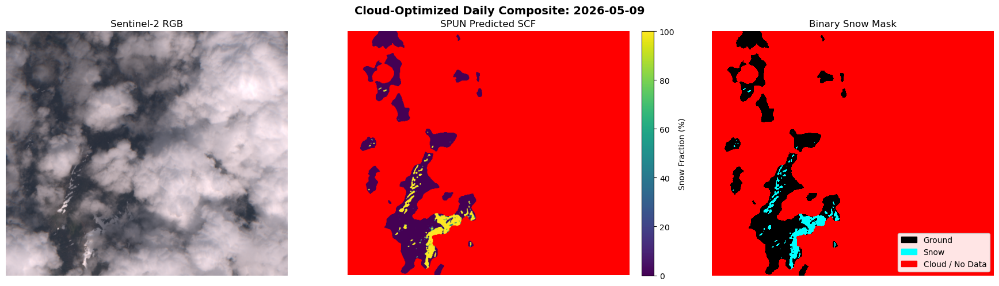

In [17]:
# 2. Predict
print("\n--- Running Inference on Optimized Mosaics ---")
for item in optimized_images:
    if item['optical'] is None: continue
        
    print(f"\nPredicting on Daily Composite: {item['date']}")
    prediction_np = predict_batched(
        model=model, image_array=item['optical'], device=device, 
        batch_size=16, num_workers=0, cloud_mask_array=item['cloud_mask']
    )
    
    plot_snow_maps(f"Cloud-Optimized Daily Composite: {item['date']}", item['optical'], prediction_np)

---

## 🌍 YOUR TURN: Test SPUN on your own mountain!

Now that you've seen how the pipeline handles overlapping passes and moving clouds, it's time to test it out on your own region of interest. 

**Step 1: Create a GeoJSON**
1. Head over to [geojson.io](https://geojson.io/).
2. Zoom into your favorite mountain range anywhere in the world.
3. Select the **Draw a Polygon** tool (the pentagon icon on the right) and draw a box over your area.
4. Go to `Export` > `GeoJSON` and download the file. 

**Step 2: Upload and Run**
1. Upload that file into the same folder as this notebook (or create a `data/` folder).
2. Change the `MY_GEOJSON` and date variables below.
3. Run the cell and see how SPUN performs!

*(Tip: Sentinel-2 optical data is completely dark during the polar night. If you pick a mountain in the high Arctic or Antarctic, make sure your dates are during their respective summer months!)*

In [19]:
# --- YOUR CONFIGURATION ---
MY_GEOJSON = 'my_custom_mountain.geojson' # <-- Change this to your uploaded file name!
MY_START = '2026-03-01'                   # <-- Pick a start date (YYYY-MM-DD)
MY_END = '2026-03-15'                     # <-- Pick an end date
MY_CLOUD_LIMIT = 50.0                     # <-- Max cloud cover % allowed

# 1. Load your custom geometry
with open(MY_GEOJSON, 'r') as f:
    custom_coords = json.load(f)['features'][0]['geometry']['coordinates']
custom_roi = ee.Geometry.Polygon(custom_coords)

# 2. Fetch the cloud-optimized data
print(f"Fetching best available data for your ROI between {MY_START} and {MY_END}...")
custom_images = get_daily_cloud_optimized_mosaics(
    roi=custom_roi, 
    start_date=MY_START, 
    end_date=MY_END, 
    bands=BANDS,
    max_cloud_cover=MY_CLOUD_LIMIT
)

# 3. Predict and Plot!
if not custom_images:
    print("No clear images found. Try a wider date range or a higher cloud limit!")
else:
    print("\n--- Running SPUN on your custom ROI ---")
    for item in custom_images:
        if item['optical'] is None: continue
            
        prediction_np = predict_batched(
            model=model, # Using the model we already loaded earlier!
            image_array=item['optical'], 
            device=device, 
            batch_size=16, 
            num_workers=0, 
            cloud_mask_array=item['cloud_mask']
        )
        
        plot_snow_maps(f"Your ROI - Best Pixels for {item['date']}", item['optical'], prediction_np)

## Example export to Geotiff

In [41]:
import json
from src.utils.export_utils import export_prediction_to_geotiff, export_rgb_to_geotiff

# --- YOUR CONFIGURATION ---
MY_LOCATION_NAME = 'My_Mountain'          # <-- Prefix for your saved files!

if not custom_images:
    print("No clear images found. Try a wider date range or a higher cloud limit!")
else:
    print("\n--- Running SPUN on your custom ROI ---")
    for item in custom_images:
        if item['optical'] is None: continue
            
        prediction_np = predict_batched(
            model=model, 
            image_array=item['optical'], 
            device=device, 
            batch_size=16, 
            num_workers=0, 
            cloud_mask_array=item['cloud_mask']
        )
                
        # --- EXPORTS ---
        # Pass the custom prefix (e.g., 'My_Mountain_RGB')
        export_rgb_to_geotiff(
            img_array=item['optical'], 
            date_str=item['date'], 
            roi=custom_roi, 
            prefix=f"{MY_LOCATION_NAME}_RGB"
        )
        export_prediction_to_geotiff(
            prediction_np=prediction_np, 
            date_str=item['date'], 
            roi=custom_roi, 
            prefix=f"{MY_LOCATION_NAME}_SPUN_SCF"
        )
        print("-" * 40)

---
## Mount Loch - Australia 
An example outside Scotland where SPUN was trained.

In [29]:
# --- YOUR CONFIGURATION ---
MY_GEOJSON = 'australia_mount_loch.geojson' # <-- Change this to your uploaded file name!
MY_START = '2017-11-01'                   # <-- Pick a start date (YYYY-MM-DD)
MY_END = '2017-12-15'                     # <-- Pick an end date
MY_CLOUD_LIMIT = 100.0                     # <-- Max cloud cover % allowed

# 1. Load your custom geometry
with open(MY_GEOJSON, 'r') as f:
    custom_coords = json.load(f)['features'][0]['geometry']['coordinates']
custom_roi = ee.Geometry.Polygon(custom_coords)

# 2. Fetch the cloud-optimized data
print(f"Fetching best available data for your ROI between {MY_START} and {MY_END}...")
custom_images = get_daily_cloud_optimized_mosaics(
    roi=custom_roi, 
    start_date=MY_START, 
    end_date=MY_END, 
    bands=BANDS,
    max_cloud_cover=MY_CLOUD_LIMIT
)



Fetching best available data for your ROI between 2017-11-01 and 2017-12-15...
Found 6 raw tiles grouped into 6 unique day(s).
Analyzing daily composite for: 2017-11-04...
  -> Composite is 0.0% cloudy. Downloading 13-band optical data...
Analyzing daily composite for: 2017-11-09...
  -> Composite is 0.0% cloudy. Downloading 13-band optical data...
Analyzing daily composite for: 2017-11-19...
  -> Composite is 72.0% cloudy. Downloading 13-band optical data...
Analyzing daily composite for: 2017-11-24...
  -> Composite is 100.0% cloudy. Downloading 13-band optical data...
Analyzing daily composite for: 2017-12-09...
  -> Composite is 0.0% cloudy. Downloading 13-band optical data...
Analyzing daily composite for: 2017-12-14...
  -> Composite is 100.0% cloudy. Downloading 13-band optical data...



--- Running SPUN on your custom ROI ---


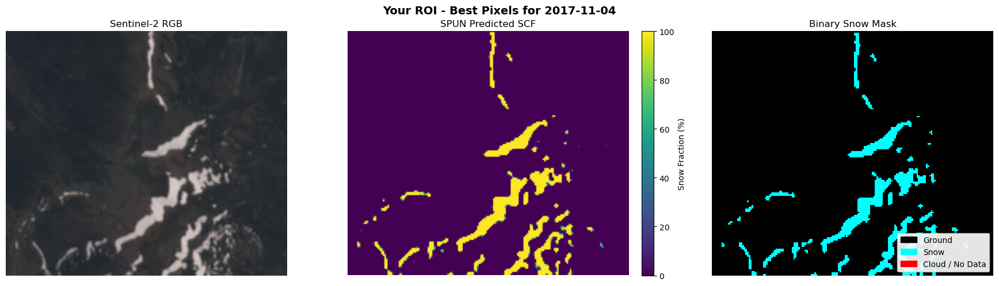

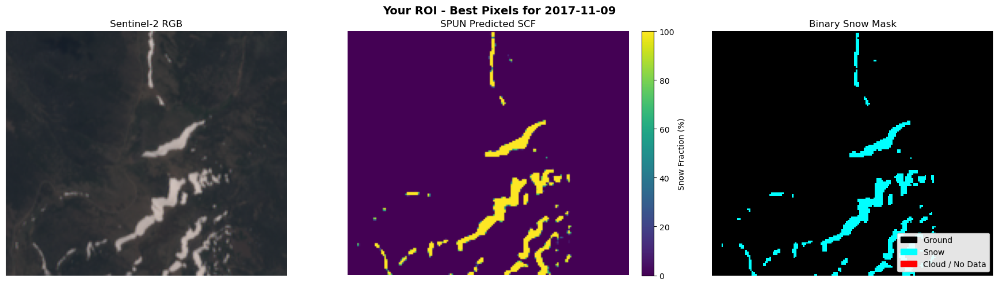

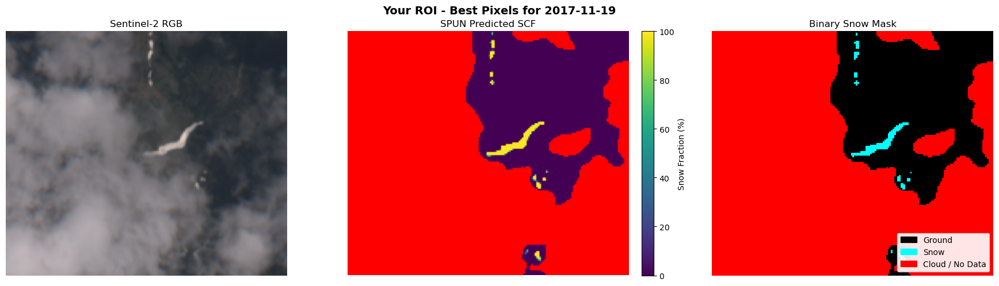

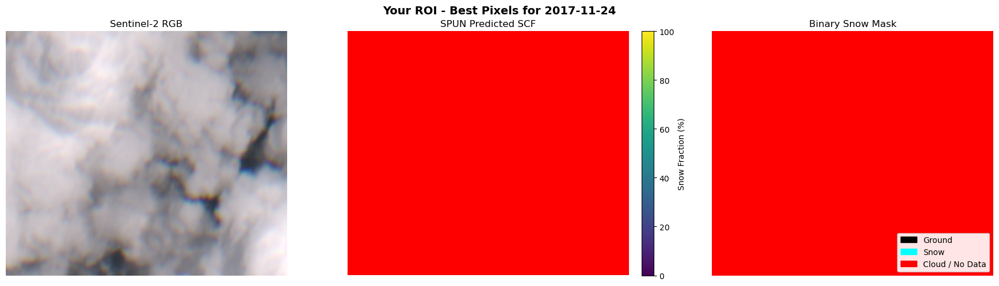

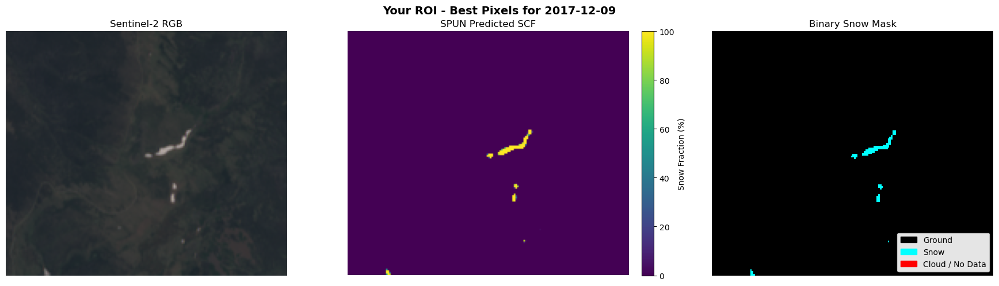

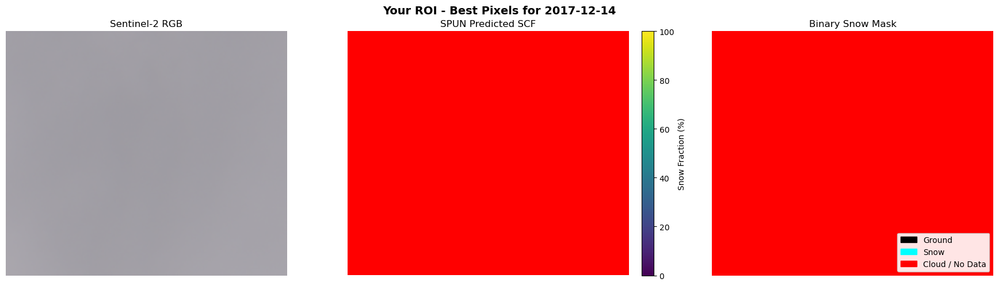

In [33]:
# 3. Predict and Plot!
if not custom_images:
    print("No clear images found. Try a wider date range or a higher cloud limit!")
else:
    print("\n--- Running SPUN on your custom ROI ---")
    for item in custom_images:
        if item['optical'] is None: continue
            
        prediction_np = predict_batched(
            model=model, # Using the model we already loaded earlier!
            image_array=item['optical'], 
            device=device, 
            batch_size=16, 
            num_workers=0, 
            cloud_mask_array=item['cloud_mask']
        )
        
        plot_snow_maps(f"Your ROI - Best Pixels for {item['date']}", item['optical'], prediction_np)